In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings('ignore')

try:
    import umap  # pip install umap-learn
    HAS_UMAP = True
except ImportError:
    HAS_UMAP = False

In [2]:
# Настройки отображения
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = [12, 8]
plt.rcParams['figure.dpi'] = 100

In [5]:
# Считываем датасет EEG-Eye-State
df = pd.read_csv('/content/EEG-Eye-State.csv')
df

,AF3,AF4,F3,F4,F7,F8,FC5,FC6,T7,T8,P7,P8,O1,O2,eyeDetection
0,4329.23,4393.85,4289.23,4280.51,4009.23,4635.90,4148.21,4211.28,4350.26,4238.46,4586.15,4222.05,4096.92,4641.03,0
1,4324.62,4384.10,4293.85,4279.49,4004.62,4632.82,4148.72,4207.69,4342.05,4226.67,4586.67,4210.77,4097.44,4638.97,0
2,4327.69,4389.23,4295.38,4282.05,4006.67,4628.72,4156.41,4206.67,4336.92,4222.05,4583.59,4207.69,4096.92,4630.26,0
3,4328.72,4396.41,4296.41,4287.69,4011.79,4632.31,4155.90,4210.77,4343.59,4235.38,4582.56,4217.44,4097.44,4630.77,0
4,4326.15,4398.46,4292.31,4288.21,4011.79,4632.82,4151.28,4212.82,4347.69,4244.10,4586.67,4210.77,4095.90,4627.69,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14975,4281.03,4340.51,4245.64,4269.23,3990.26,4593.33,4116.92,4171.28,4333.85,4221.54,4614.36,4203.08,4074.87,4625.64,1
14976,4276.92,4333.33,4245.13,4259.49,3991.79,4590.26,4110.77,4162.56,4332.82,4217.44,4615.38,4194.36,4073.33,4621.54,1
14977,4277.44,4339.49,4246.67,4257.95,3990.77,4591.79,4113.85,4160.51,4333.33,4212.82,4615.38,4193.33,4072.82,4623.59,1
14978,4284.62,4350.77,4251.28,4267.18,3991.79,4596.41,4122.05,4165.64,4334.36,4220.00,4616.41,4200.00,4080.51,4628.72,1


In [6]:
df.describe()

,AF3,AF4,F3,F4,F7,F8,FC5,FC6,T7,T8,P7,P8,O1,O2,eyeDetection
count,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000
mean,4321.917777,4416.435832,4264.022433,4279.232774,4009.767694,4615.205336,4164.946326,4202.456900,4341.741075,4231.316200,4644.022379,4218.826610,4110.400160,4616.056904,0.448798
std,2492.072174,5891.285043,44.428052,41.544312,45.941672,1208.369958,5216.404632,37.785981,34.738821,38.050903,2924.789537,2136.408523,4600.926543,29.292603,0.497388
min,1030.770000,1366.150000,1040.000000,2257.950000,2830.770000,86.666700,2453.330000,3273.330000,2089.740000,1816.410000,2768.210000,1357.950000,2086.150000,4567.180000,0.000000
25%,4280.510000,4342.050000,4250.260000,4267.690000,3990.770000,4590.770000,4108.210000,4190.260000,4331.790000,4220.510000,4611.790000,4190.770000,4057.950000,4604.620000,0.000000
50%,4294.360000,4354.870000,4262.560000,4276.920000,4005.640000,4603.080000,4120.510000,4200.510000,4338.970000,4229.230000,4617.950000,4199.490000,4070.260000,4613.330000,0.000000
75%,4311.790000,4372.820000,4270.770000,4287.180000,4023.080000,4617.440000,4132.310000,4211.280000,4347.180000,4239.490000,4626.670000,4209.230000,4083.590000,4624.100000,1.000000
max,309231.000000,715897.000000,6880.510000,7002.560000,7804.620000,152308.000000,642564.000000,6823.080000,6474.360000,6674.360000,362564.000000,265641.000000,567179.000000,7264.100000,1.000000


## В данных есть выбросы, которые нужно убрать

In [7]:
q = 0.999

feature_names = [x for x in df.columns if x != 'eyeDetection']
for feature in feature_names:
    df = df[df[feature] < df[feature].quantile(q)]
df

,AF3,AF4,F3,F4,F7,F8,FC5,FC6,T7,T8,P7,P8,O1,O2,eyeDetection
0,4329.23,4393.85,4289.23,4280.51,4009.23,4635.90,4148.21,4211.28,4350.26,4238.46,4586.15,4222.05,4096.92,4641.03,0
1,4324.62,4384.10,4293.85,4279.49,4004.62,4632.82,4148.72,4207.69,4342.05,4226.67,4586.67,4210.77,4097.44,4638.97,0
2,4327.69,4389.23,4295.38,4282.05,4006.67,4628.72,4156.41,4206.67,4336.92,4222.05,4583.59,4207.69,4096.92,4630.26,0
3,4328.72,4396.41,4296.41,4287.69,4011.79,4632.31,4155.90,4210.77,4343.59,4235.38,4582.56,4217.44,4097.44,4630.77,0
4,4326.15,4398.46,4292.31,4288.21,4011.79,4632.82,4151.28,4212.82,4347.69,4244.10,4586.67,4210.77,4095.90,4627.69,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14975,4281.03,4340.51,4245.64,4269.23,3990.26,4593.33,4116.92,4171.28,4333.85,4221.54,4614.36,4203.08,4074.87,4625.64,1
14976,4276.92,4333.33,4245.13,4259.49,3991.79,4590.26,4110.77,4162.56,4332.82,4217.44,4615.38,4194.36,4073.33,4621.54,1
14977,4277.44,4339.49,4246.67,4257.95,3990.77,4591.79,4113.85,4160.51,4333.33,4212.82,4615.38,4193.33,4072.82,4623.59,1
14978,4284.62,4350.77,4251.28,4267.18,3991.79,4596.41,4122.05,4165.64,4334.36,4220.00,4616.41,4200.00,4080.51,4628.72,1


In [8]:
df.describe()

,AF3,AF4,F3,F4,F7,F8,FC5,FC6,T7,T8,P7,P8,O1,O2,eyeDetection
count,14760.000000,14760.000000,14760.000000,14760.000000,14760.000000,14760.000000,14760.000000,14760.000000,14760.000000,14760.000000,14760.000000,14760.000000,14760.000000,14760.000000,14760.000000
mean,4299.809106,4359.658411,4262.961930,4277.931711,4008.462131,4604.437060,4121.368542,4200.786828,4340.641390,4230.153348,4619.094776,4200.434656,4071.940484,4614.900810,0.450474
std,35.473707,36.013527,18.991537,17.608417,28.562678,30.678969,18.851415,21.674630,14.247183,17.214716,15.228522,15.549795,19.172849,16.136764,0.497558
min,4197.950000,4205.640000,4197.440000,4201.030000,3905.640000,4443.080000,4058.460000,4100.000000,4304.620000,4152.820000,4566.150000,4147.690000,4026.150000,4567.180000,0.000000
25%,4280.510000,4341.540000,4250.260000,4267.180000,3990.260000,4590.260000,4108.210000,4189.740000,4331.790000,4220.000000,4611.790000,4190.770000,4057.950000,4604.620000,0.000000
50%,4293.850000,4354.870000,4262.560000,4276.410000,4005.130000,4603.080000,4120.510000,4200.000000,4338.970000,4229.230000,4617.950000,4199.490000,4070.260000,4613.330000,0.000000
75%,4310.260000,4371.790000,4270.260000,4286.670000,4022.050000,4616.920000,4131.280000,4210.770000,4346.670000,4239.490000,4626.150000,4208.720000,4083.590000,4623.590000,1.000000
max,4490.260000,4535.900000,4367.690000,4364.100000,4140.510000,4774.360000,4213.330000,4306.670000,4428.720000,4312.310000,4705.130000,4274.360000,4155.380000,4686.150000,1.000000


## Теперь выбросов нет, можно работать с данными

In [9]:
df['eyeDetection'].value_counts()

,count
eyeDetection,
0,8111
1,6649


## Датасет сбалансирован относительно таргета

In [10]:
# На Kaggle для датасета указано, что 0 - это Closed (глаз закрыт), а 1 - Open Eyes (глаз открыт)
target_class_names_dict = {
    0: 'Closed',
    1: 'Open Eyes'
}


Информация о данных:
  Размер: (14760, 14)
  Количество классов: 2
  Количество признаков: 14
  Минимум: -5.260, Максимум: 6.182
  Среднее: 0.000, Стандартное отклонение: 1.000
ПОЛНАЯ ВИЗУАЛИЗАЦИЯ МНОГОМЕРНЫХ ДАННЫХ

1. Парные диаграммы рассеяния (PairPlot)


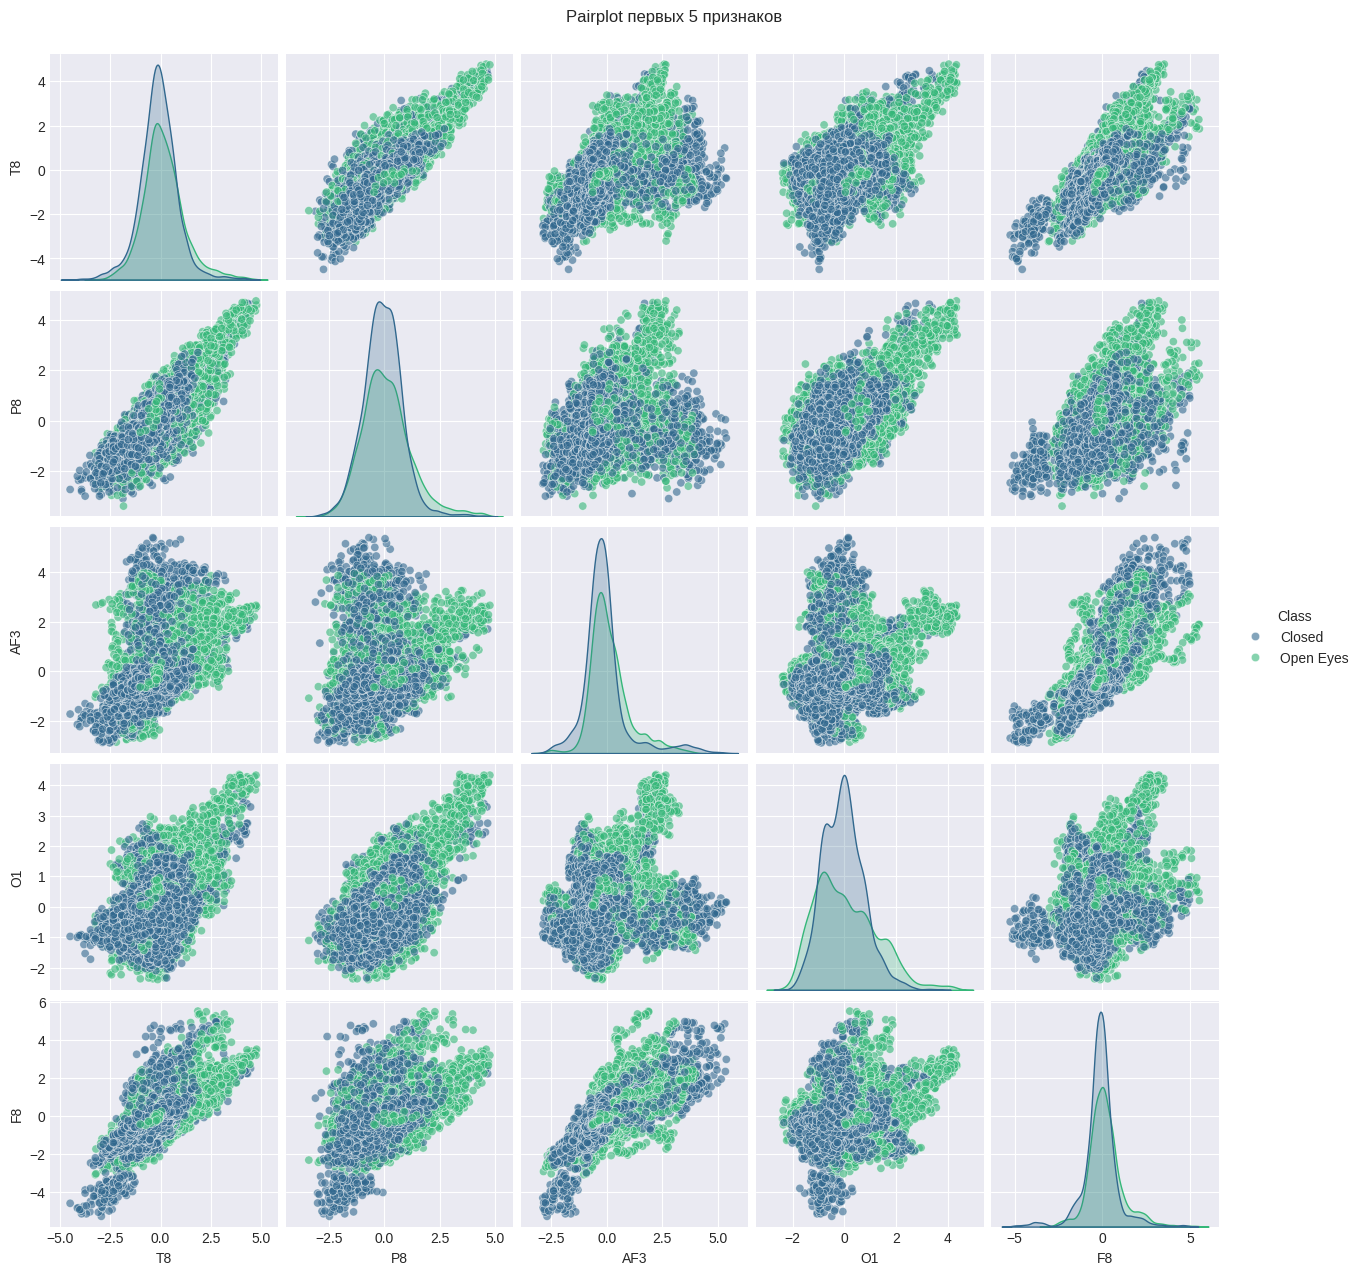


2. Тепловая карта корреляций


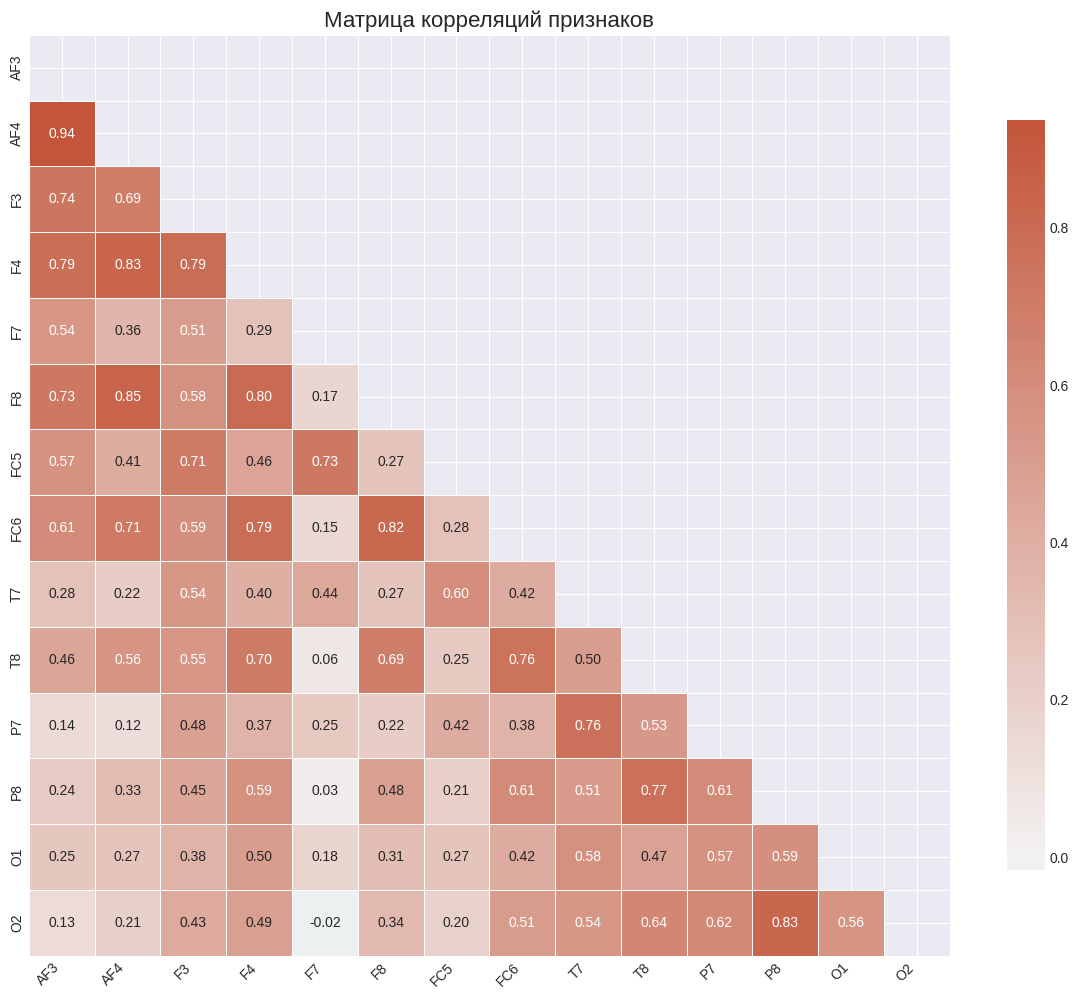


3. Визуализация PCA (2D и 3D)
Объясненная дисперсия: [0.52430889 0.16607133 0.1327875 ]
Суммарная объясненная дисперсия: 0.823


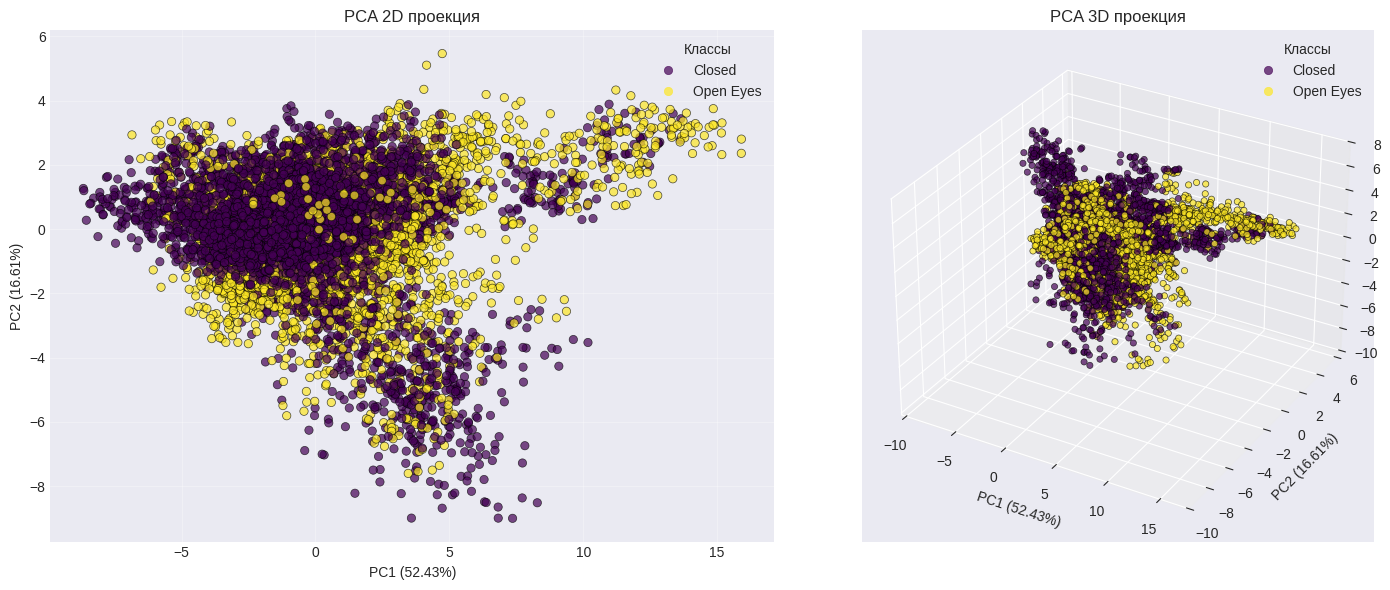

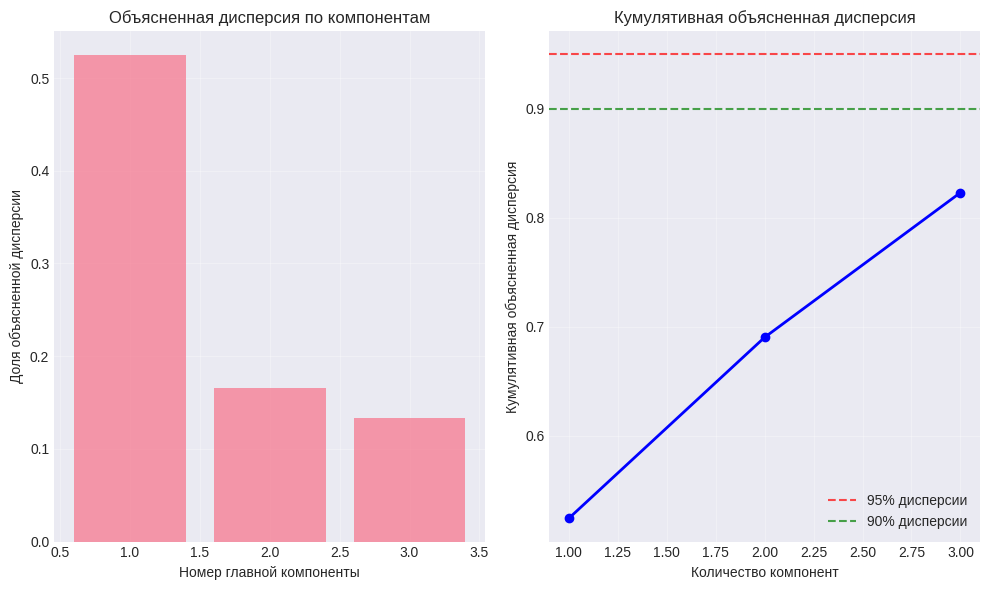


4. Визуализация t-SNE


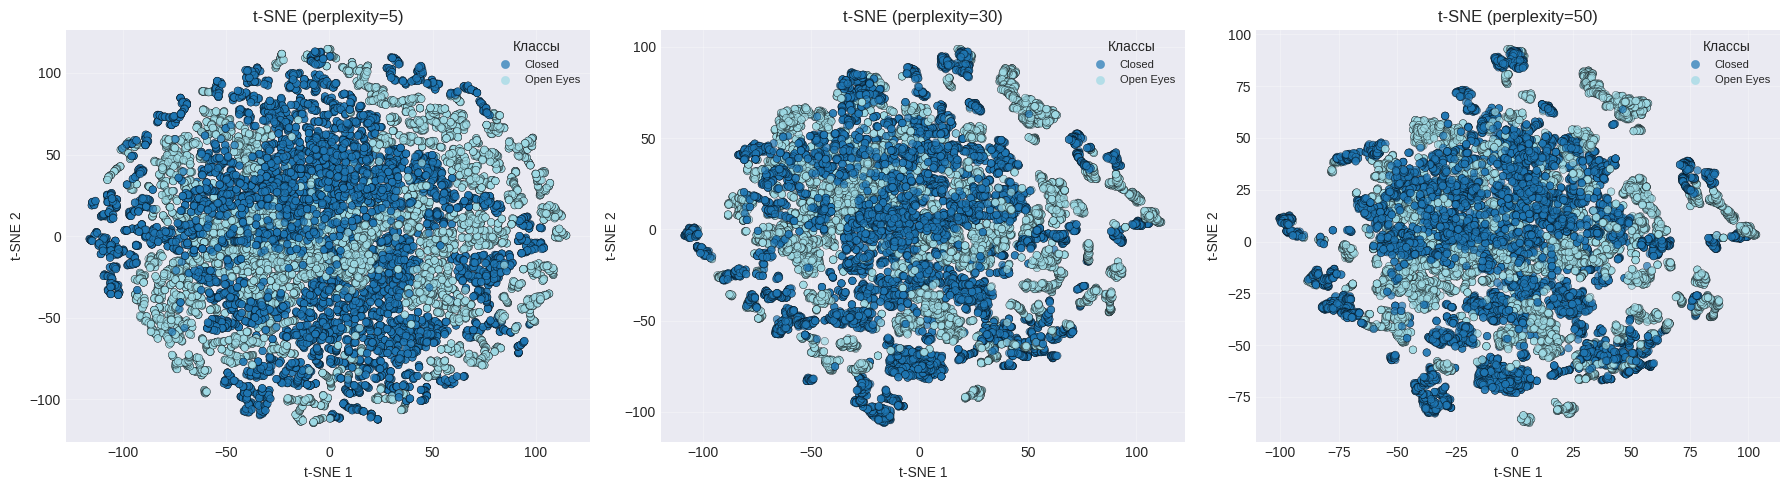


5. Визуализация UMAP


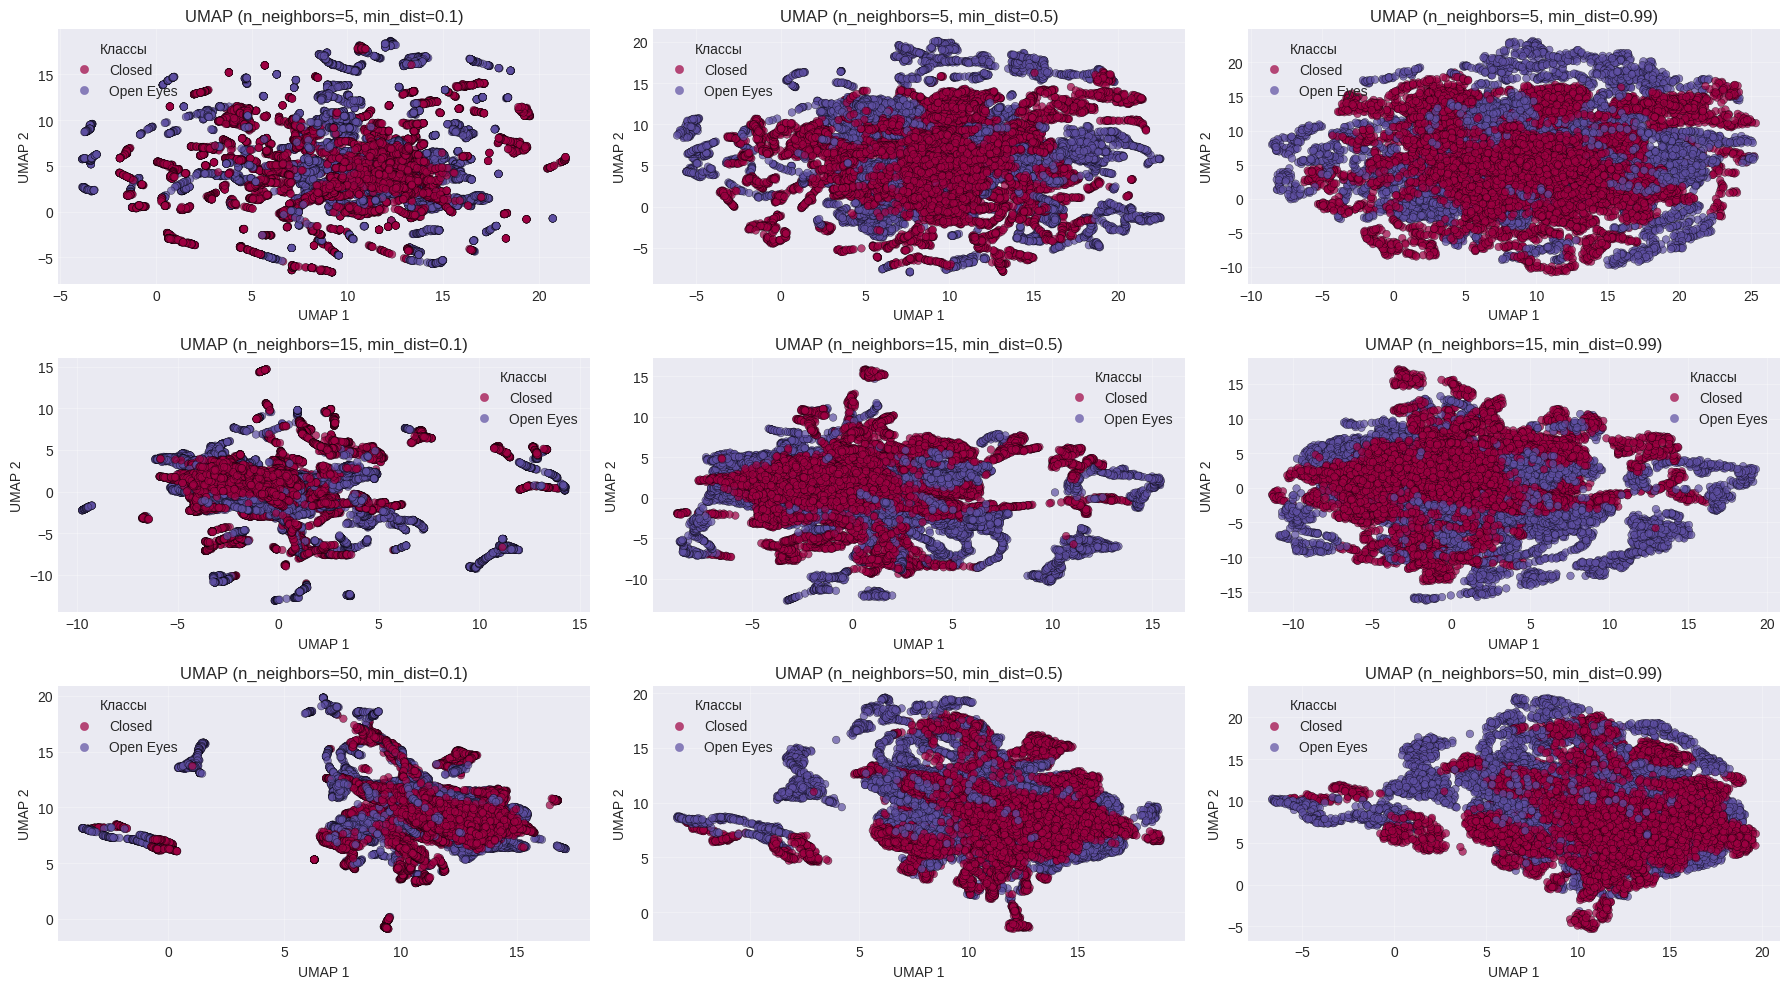


6. Параллельные координаты


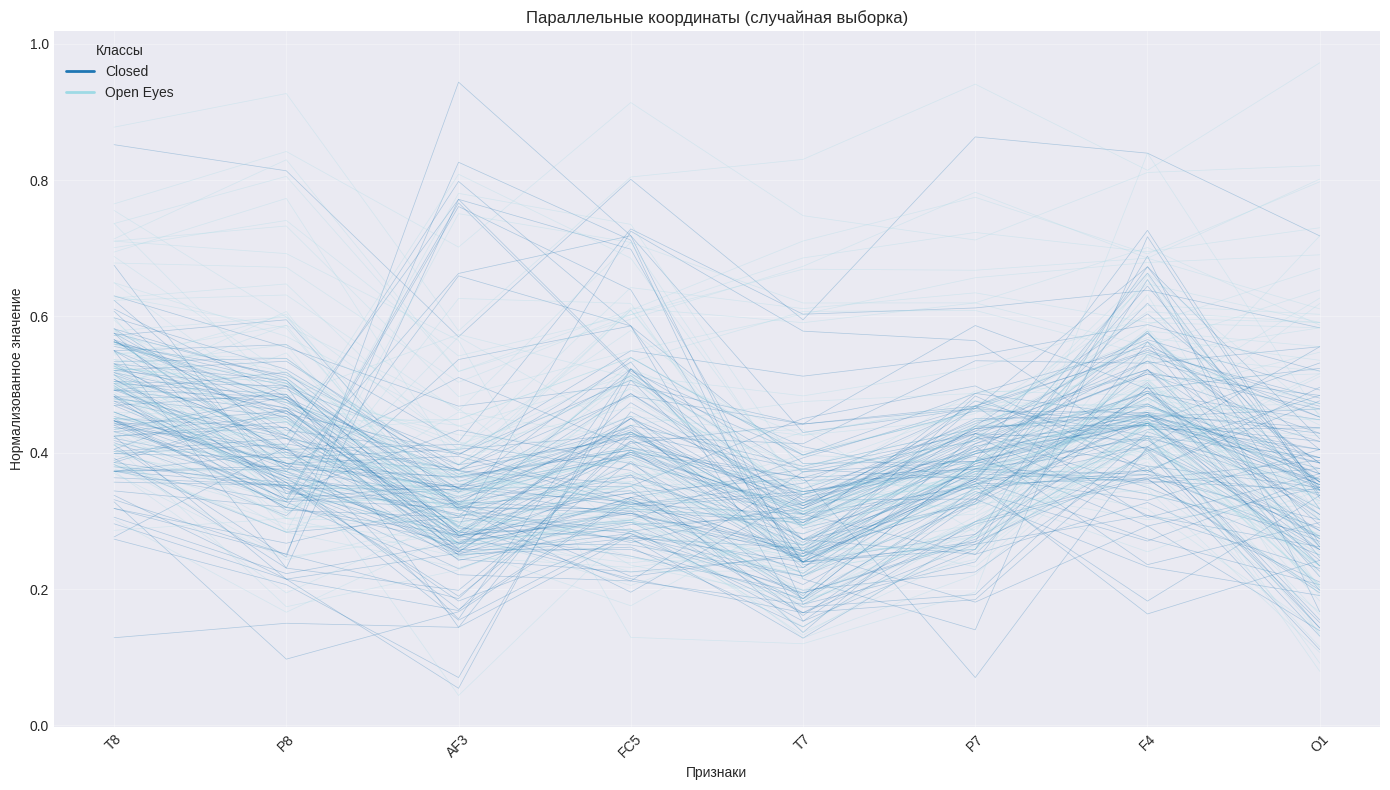


7. Радар-чарты по классам


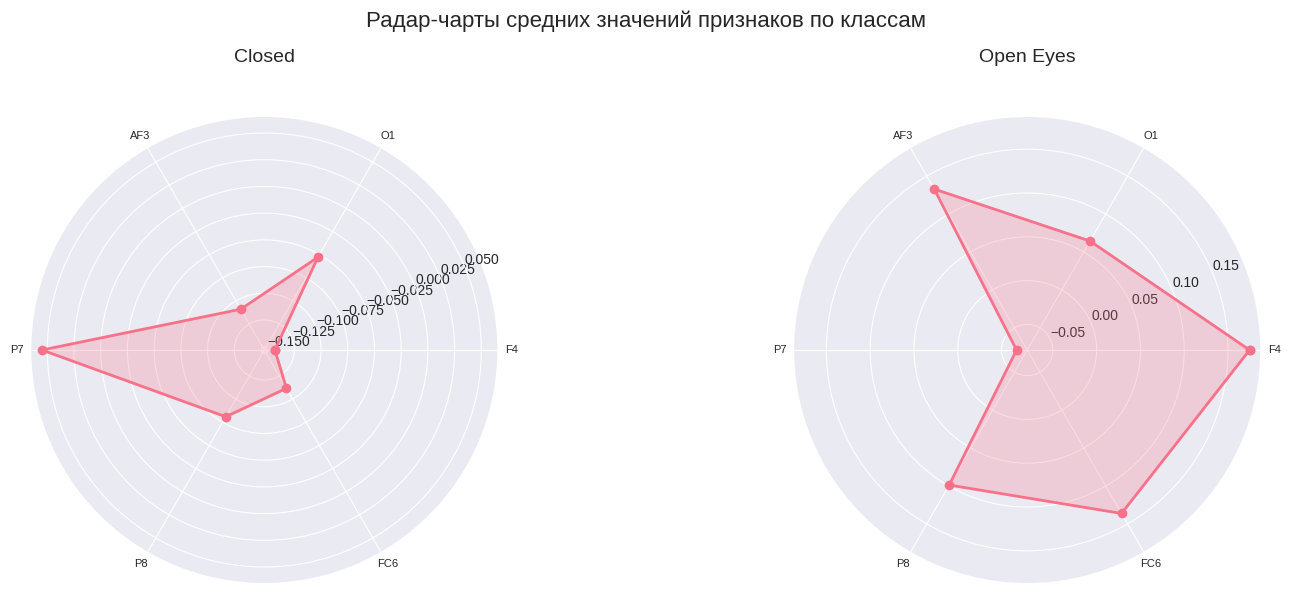


8. Интерактивная 3D визуализация (откроется в браузере)
  График сохранен в файл: interactive_3d_plot.html



9. Сравнение методов уменьшения размерности
  Применяем PCA...
  Применяем t-SNE...
  Применяем Isomap...
  Применяем UMAP...


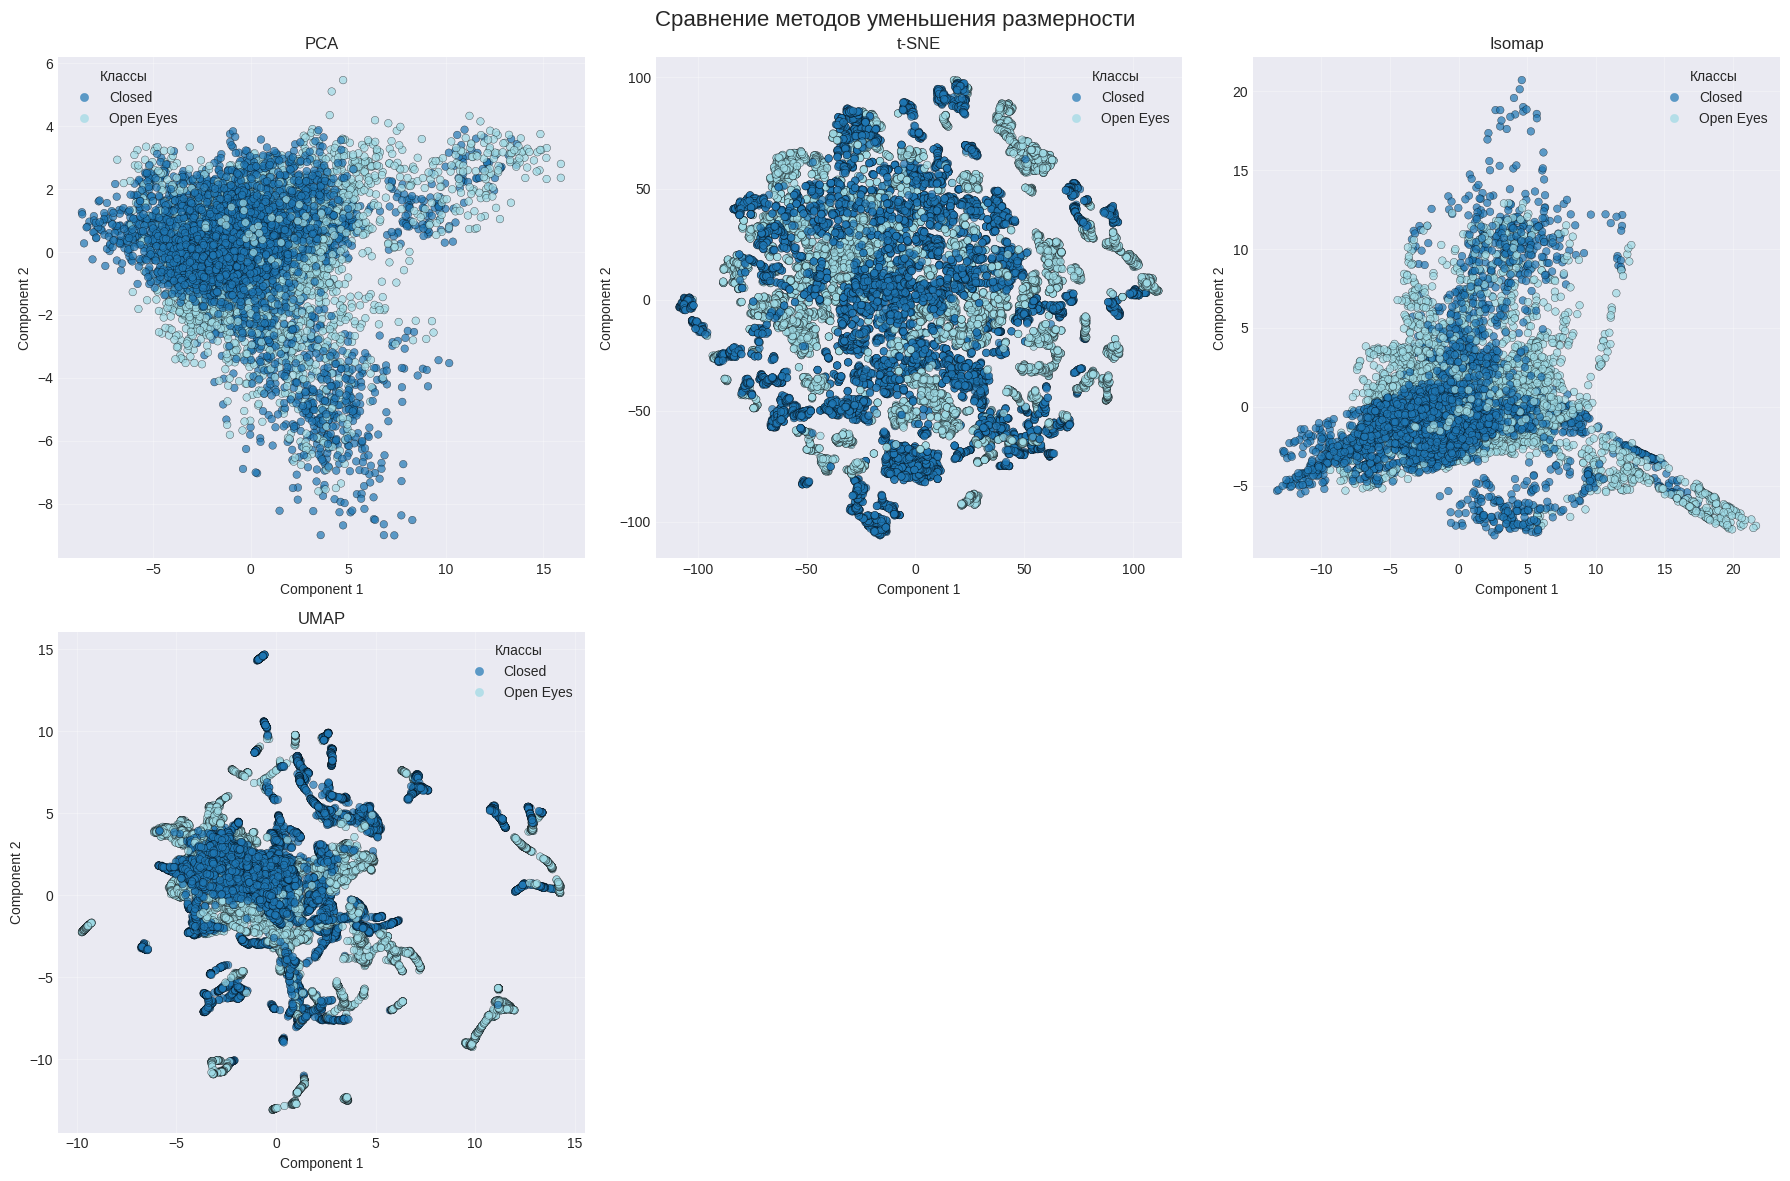


ВИЗУАЛИЗАЦИЯ ЗАВЕРШЕНА


In [12]:
from multidim_visualization import HighDimVisualizer

visualizer = HighDimVisualizer(random_state=42)

# Загрузка датасета и других параметров в визуализатор
# StandardScaler() добавлен для того, чтобы в радар-чартах была видна разница между классами, так как данные находятся примерно в диапазоне 1000-7000
visualizer.load_dataset(df, target_column='eyeDetection', scaler=StandardScaler(), target_class_names=target_class_names_dict)

# Запуск визуализации
visualizer.run_full_visualization()